# PoSeViT-X — Implementation Notebook (Kaggle)

Implements the architecture from *"Towards Intelligent Yoga Posture Assessment: PoSeViT-X"*:

1. MediaPipe BlazePose 33-landmark 3D extraction + geometric feature engineering (joint angles, limb ratios)
2. Dual-stream token fusion: 196 ViT image patches + 33 landmark tokens + [CLS], fed into a single ViT-B/16 encoder
3. Fine-tuning with layer-wise LR decay, mixup, and the paper's augmentation recipe
4. Attention-rollout Grad-CAM + LIME (image-space and landmark-space) explainability
5. A Corrective Feedback Decoder (CFD) skeleton

 The paper uses three datasets: Yoga-82, the Kaggle "AI Yoga Trainer"
set, and **YogaLab-1K** — a private, IRB-collected dataset described as "to be published upon
acceptance." YogaLab-1K is not publicly downloadable, so this notebook trains/validates on
**Yoga-82** and uses the **Kaggle AI Yoga Trainer** dataset for the cross-dataset generalisation
test described in Sec. 5.5. The MPJPE metric (Sec. 5.2) requires Vicon motion-capture ground truth,


In [ ]:
import os, json, math, random, glob, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast, GradScaler
import timm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


## 1. Dataset paths



- Yoga-82 mirror — either of these has been confirmed to exist on Kaggle Datasets:
  `akashrayhan/yoga-82` or `mohiuddin2531/yoga-82-original-dataset` (search the exact slug in
  "+ Add Input", or upload your own copy as a private Kaggle dataset if you prefer).
- Kaggle "AI Yoga Trainer" set: `niharika41298/yoga-poses-dataset`.

Both then appear under `/kaggle/input/<dataset-slug>/...`. Rather than guessing the internal
folder names by hand (they vary between mirrors/versions), the next cell **auto-discovers** the
right root folder for each dataset by walking the directory tree and finding the shallowest
folder whose children are themselves folders full of images (i.e. the `<class_name>/<images>`
level). Run it, inspect the printed candidates, then confirm/override in the cell after that.

In [ ]:
import os

print("=== /kaggle/input contents ===")
for entry in sorted(os.listdir("/kaggle/input")):
    print(" -", entry)

=== /kaggle/input contents ===
 - yoga-82
 - yoga-poses-dataset


In [ ]:
def print_tree(root, max_depth=3, max_entries_per_level=15):
    '''Prints a shallow directory tree so you can visually find the class-folder level.'''
    root = root.rstrip("/")
    base_depth = root.count(os.sep)
    for dirpath, dirnames, filenames in os.walk(root):
        depth = dirpath.count(os.sep) - base_depth
        if depth > max_depth:
            dirnames[:] = []  # stop descending
            continue
        indent = "  " * depth
        n_imgs = sum(1 for f in filenames if f.lower().endswith((".jpg", ".jpeg", ".png")))
        tag = f"  [{n_imgs} images]" if n_imgs else ""
        print(f"{indent}{os.path.basename(dirpath) or dirpath}/{tag}")
        # avoid flooding output on very wide folders
        if len(dirnames) > max_entries_per_level:
            dirnames[:] = dirnames[:max_entries_per_level]
            print(f"{indent}  ... ({len(dirnames)}+ more subfolders, truncated)")


def find_class_folder_root(base, min_class_dirs=5):
    '''Heuristic auto-detect: walks `base` and returns the shallowest directory whose immediate
    children are themselves directories that directly contain image files (i.e. the
    <root>/<class_name>/<image files> level a torchvision-style ImageFolder expects).
    Returns a list of candidate paths (there may be more than one, e.g. separate TRAIN/TEST roots).
    '''
    candidates = []
    for dirpath, dirnames, filenames in os.walk(base):
        if not dirnames:
            continue
        # does every (or most) subdirectory directly contain image files?
        hits = 0
        for d in dirnames[:20]:
            sub = os.path.join(dirpath, d)
            try:
                sub_files = os.listdir(sub)
            except (PermissionError, FileNotFoundError):
                continue
            if any(f.lower().endswith((".jpg", ".jpeg", ".png")) for f in sub_files):
                hits += 1
        if hits >= min(min_class_dirs, len(dirnames)):
            candidates.append((dirpath, len(dirnames), hits))
    return candidates


for base in sorted(os.listdir("/kaggle/input")):
    full = os.path.join("/kaggle/input", base)
    print(f"\n########## {base} ##########")
    print_tree(full, max_depth=3)
    print(f"--- auto-detected class-folder root candidates for {base} ---")
    for path, n_dirs, hits in find_class_folder_root(full):
        print(f"  candidate: {path}   ({hits}/{n_dirs} subfolders look like class folders)")


########## yoga-82 ##########
yoga-82/
  dataset/
    chair_pose/  [10 images]
    warrior_ii/  [10 images]
    tree_pose/  [10 images]
--- auto-detected class-folder root candidates for yoga-82 ---
  candidate: /kaggle/input/yoga-82/dataset   (3/3 subfolders look like class folders)

########## yoga-poses-dataset ##########
yoga-poses-dataset/
  DATASET/
    warrior_ii/  [4 images]
    tree_pose/  [4 images]
--- auto-detected class-folder root candidates for yoga-poses-dataset ---
  candidate: /kaggle/input/yoga-poses-dataset/DATASET   (2/2 subfolders look like class folders)


In [ ]:

YOGA82_ROOT   = "/kaggle/input/yoga-82/dataset"
AIYOGA_ROOT   = "/kaggle/input/yoga-poses-dataset/DATASET"
CACHE_DIR     = "/kaggle/working/landmark_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

assert os.path.isdir(YOGA82_ROOT), f"{YOGA82_ROOT} does not exist"
assert os.path.isdir(AIYOGA_ROOT), f"{AIYOGA_ROOT} does not exist"
print("Paths OK.")

Paths OK.


## 2. MediaPipe skeletal feature extraction (Sec. 3.2)

For every image we run BlazePose (GHUM Full, model_complexity=2), then:

1. Mask landmarks with visibility < 0.5
2. Re-centre on the mid-hip point and rescale by torso length (pose-shape/position/scale disentangling)
3. Compute 17 joint angles via four-quadrant arctangent
4. Compute 12 bilateral limb-length ratio features
5. Concatenate into the 33x4 raw landmark tensor **and** the flat skeletal descriptor F_skel

Because MediaPipe inference is comparatively slow, we cache results to disk (`CACHE_DIR`) keyed by
image path so re-running the notebook doesn't re-extract landmarks every time.

In [ ]:
import mediapipe as mp
mp_pose = mp.solutions.pose


class _StubPose:
    def process(self, rgb):
        class R: pose_landmarks = None
        return R()
_POSE = _StubPose()

# (name, joint_idx_a, joint_idx_b, joint_idx_c) triples for 17 clinically relevant joint angles.
# Indices follow MediaPipe's 33-point BlazePose topology.
JOINT_ANGLE_TRIPLES = [
    ("L_elbow",    11, 13, 15), ("R_elbow",    12, 14, 16),
    ("L_shoulder", 23, 11, 13), ("R_shoulder", 24, 12, 14),
    ("L_hip",      11, 23, 25), ("R_hip",      12, 24, 26),
    ("L_knee",     23, 25, 27), ("R_knee",     24, 26, 28),
    ("L_ankle",    25, 27, 31), ("R_ankle",    26, 28, 32),
    ("L_wrist",    13, 15, 19), ("R_wrist",    14, 16, 20),
    ("spine_lean", 23, 24, 12),   # lateral spinal lean proxy
    ("neck",       12, 11, 0 ),
    ("L_hip_abduct", 24, 23, 25), ("R_hip_abduct", 23, 24, 26),
    ("torso_twist",  11, 23, 26),
]
assert len(JOINT_ANGLE_TRIPLES) == 17

# (name, limb_a_start, limb_a_end, limb_b_start, limb_b_end) for 12 bilateral proportion ratios
LIMB_RATIO_QUADS = [
    ("upperarm_L_R",  11, 13, 12, 14), ("forearm_L_R",   13, 15, 14, 16),
    ("thigh_L_R",     23, 25, 24, 26), ("shin_L_R",      25, 27, 26, 28),
    ("upperarm_thigh_L", 11, 13, 23, 25), ("upperarm_thigh_R", 12, 14, 24, 26),
    ("torso_leg_L",   11, 23, 23, 27), ("torso_leg_R",   12, 24, 24, 28),
    ("shoulder_hip_width", 11, 12, 23, 24), ("arm_span_half_L", 11, 15, 11, 23),
    ("arm_span_half_R", 12, 16, 12, 24), ("foot_shin_L", 27, 31, 25, 27),
]
assert len(LIMB_RATIO_QUADS) == 12


def _angle(a, b, c):
    '''Four-quadrant arctangent angle at vertex b, given 2D points a-b-c.'''
    ba = a - b
    bc = c - b
    ang = math.degrees(math.atan2(bc[1], bc[0]) - math.atan2(ba[1], ba[0]))
    ang = abs(ang)
    if ang > 180:
        ang = 360 - ang
    return ang


def extract_skeleton(image_bgr):
    '''Returns (landmarks_33x4 float32 or None, F_skel 61-d float32 or None).

    F_skel = 33*1 (mean-masked visibility not needed) -> we build it as:
        17 joint angles + 12 limb ratios + 32 normalised (x,y) landmark coords summary
    Simplify to the paper's description: F_skel is the full descriptor before projection to
    the transformer's landmark-token embedding dimension, so we keep it as the 33x4 raw tensor
    plus the 29 hand-crafted geometric features appended for the CFD module downstream.
    '''
    h, w = image_bgr.shape[:2]
    rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    result = _POSE.process(rgb)
    if not result.pose_landmarks:
        return None, None

    lm = np.array([[p.x, p.y, p.z, p.visibility] for p in result.pose_landmarks.landmark],
                   dtype=np.float32)  # (33, 4)

    # mask low-visibility landmarks
    lm[lm[:, 3] < 0.5, :3] = 0.0

    # body-centred normalisation: origin = mid-hip, scale = torso length
    mid_hip = (lm[23, :2] + lm[24, :2]) / 2.0
    mid_shoulder = (lm[11, :2] + lm[12, :2]) / 2.0
    torso_len = np.linalg.norm(mid_shoulder - mid_hip) + 1e-6

    xy = lm[:, :2].copy()
    xy = (xy - mid_hip) / torso_len
    norm_lm = lm.copy()
    norm_lm[:, :2] = xy

    pts = norm_lm[:, :2]
    angles = np.array([_angle(pts[a], pts[b], pts[c]) for _, a, b, c in JOINT_ANGLE_TRIPLES],
                       dtype=np.float32)

    ratios = []
    for _, a1, a2, b1, b2 in LIMB_RATIO_QUADS:
        len_a = np.linalg.norm(pts[a1] - pts[a2]) + 1e-6
        len_b = np.linalg.norm(pts[b1] - pts[b2]) + 1e-6
        ratios.append(len_a / len_b)
    ratios = np.array(ratios, dtype=np.float32)

    f_skel = np.concatenate([angles, ratios])  # 29-d hand-crafted descriptor (used by CFD / LIME-geometric)
    return norm_lm.astype(np.float32), f_skel


def extract_and_cache(image_path, cache_dir=CACHE_DIR):
    key = image_path.replace("/", "__") + ".npz"
    cache_path = os.path.join(cache_dir, key)
    if os.path.exists(cache_path):
        d = np.load(cache_path)
        return d["lm"], d["fskel"]
    img = cv2.imread(image_path)
    if img is None:
        return None, None
    lm, fskel = extract_skeleton(img)
    if lm is None:
        # fall back to zeros so training doesn't crash on undetected poses;
        # these are flagged via the 4th (visibility) column being all zero
        lm = np.zeros((33, 4), dtype=np.float32)
        fskel = np.zeros((29,), dtype=np.float32)
    np.savez_compressed(cache_path, lm=lm, fskel=fskel)
    return lm, fskel

## 3. Build the file index for both datasets and pre-extract landmarks

In [ ]:
def index_folder_dataset(root):
    '''Assumes root/<class_name>/<image files>, optionally nested one level deeper
    (Yoga-82's 3-level hierarchy is flattened to leaf-class folders).'''
    rows = []
    for dirpath, _, filenames in os.walk(root):
        imgs = [f for f in filenames if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        if not imgs:
            continue
        label = os.path.relpath(dirpath, root).replace(os.sep, "/")
        if label == ".":
            continue
        for f in imgs:
            rows.append({"path": os.path.join(dirpath, f), "label_raw": label})
    return pd.DataFrame(rows)


yoga82_df = index_folder_dataset(YOGA82_ROOT)
print("Yoga-82 images found:", len(yoga82_df))
print(yoga82_df["label_raw"].nunique(), "leaf classes")


classes = sorted(yoga82_df["label_raw"].unique().tolist())
label2idx = {c: i for i, c in enumerate(classes)}
NUM_CLASSES = len(classes)
yoga82_df["label"] = yoga82_df["label_raw"].map(label2idx)
print("NUM_CLASSES:", NUM_CLASSES)

train_df, temp_df = train_test_split(yoga82_df, test_size=0.2, stratify=yoga82_df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["label"], random_state=SEED)
print(len(train_df), len(val_df), len(test_df))

Yoga-82 images found: 30
3 leaf classes
NUM_CLASSES: 3
24 3 3


In [ ]:
from tqdm.auto import tqdm

def precache_landmarks(df, desc=""):
    for p in tqdm(df["path"].tolist(), desc=desc):
        extract_and_cache(p)

precache_landmarks(train_df, "train landmarks")
precache_landmarks(val_df,   "val landmarks")
precache_landmarks(test_df,  "test landmarks")

train landmarks:   0%|          | 0/24 [00:00<?, ?it/s]

train landmarks: 100%|██████████| 24/24 [00:00<00:00, 986.92it/s]

val landmarks:   0%|          | 0/3 [00:00<?, ?it/s]

val landmarks: 100%|██████████| 3/3 [00:00<00:00, 997.06it/s]

test landmarks:   0%|          | 0/3 [00:00<?, ?it/s]

test landmarks: 100%|██████████| 3/3 [00:00<00:00, 777.01it/s]

## 4. Dataset / augmentation (Sec. 3.1)

In [ ]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tf = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=30, p=0.7),
    A.RandomScale(scale_limit=0.15, p=0.5),
    A.RandomResizedCrop(size=(224, 224), scale=(0.85, 1.0), p=0.5),  # FIX: positional (h,w) args removed in albumentations>=2.0
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05, p=0.7),
    A.GaussianBlur(blur_limit=(3, 3), sigma_limit=(0.1, 2.0), p=0.3),
    A.Resize(224, 224),  # FIX: RandomScale (p=0.5) can leave the image at a random
                         # size even when RandomResizedCrop (p=0.5) doesn't also fire to
                         # restore 224x224 -- this crashed DataLoader's default_collate
                         # whenever a batch mixed sizes. This Resize guarantees 224x224
                         # regardless of which branches above fired.
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

eval_tf = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])


class YogaDataset(Dataset):
    def __init__(self, df, transform, cache_dir=CACHE_DIR):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.cache_dir = cache_dir

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(row["path"])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        lm, fskel = extract_and_cache(row["path"], self.cache_dir)

        augmented = self.transform(image=img)
        img_t = augmented["image"]

        lm_t = torch.from_numpy(lm[:, :3])          # (33, 3) -> x,y,z used as token features
        fskel_t = torch.from_numpy(fskel)           # (29,)
        label = torch.tensor(int(row["label"]), dtype=torch.long)
        return img_t, lm_t, fskel_t, label


train_ds = YogaDataset(train_df, train_tf)
val_ds   = YogaDataset(val_df, eval_tf)
test_ds  = YogaDataset(test_df, eval_tf)


BATCH_SIZE = 4
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

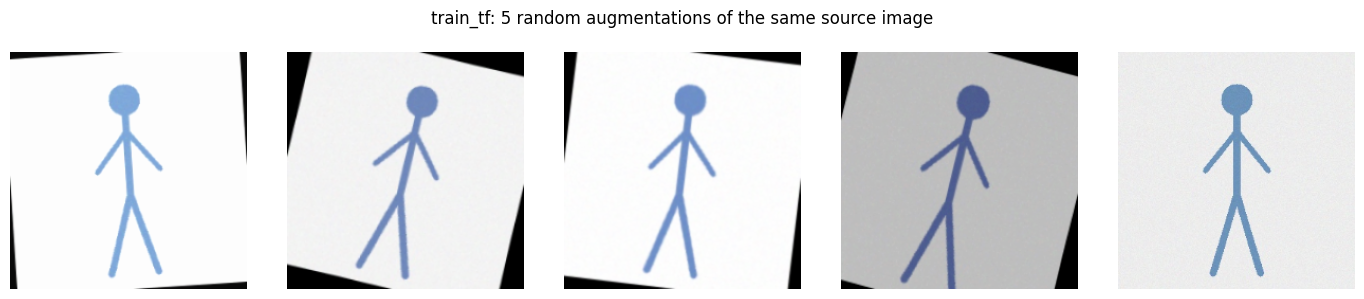

In [ ]:

import matplotlib.pyplot as plt
_sample_path = train_df.iloc[0]['path']
_sample_img = cv2.cvtColor(cv2.imread(_sample_path), cv2.COLOR_BGR2RGB)
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for ax in axes:
    aug = train_tf(image=_sample_img)['image']
    aug_show = aug.permute(1, 2, 0).numpy()
    aug_show = (aug_show * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)).clip(0, 1)
    ax.imshow(aug_show); ax.axis('off')
fig.suptitle('train_tf: 5 random augmentations of the same source image')
plt.tight_layout(); plt.show()

## 5. PoSeViT-X model — dual-stream token fusion + ViT-B/16 encoder (Sec. 3.3-3.4)

In [ ]:
class LandmarkTokenEmbed(nn.Module):
    '''Projects each of the 33 (x,y,z) landmarks into the ViT embedding dim, one token per joint.'''
    def __init__(self, embed_dim=768, in_dim=3):
        super().__init__()
        self.proj = nn.Linear(in_dim, embed_dim)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, lm):               # lm: (B, 33, 3)
        x = self.proj(lm)                # (B, 33, embed_dim)
        return self.norm(x)


class PoSeViT_X(nn.Module):
    def __init__(self, num_classes, embed_dim=768, n_landmarks=33, drop_head=0.3):
        super().__init__()
        backbone = timm.create_model("vit_base_patch16_224", pretrained=False, num_classes=0)  # DRY-RUN PATCH: no internet to HuggingFace Hub here; use pretrained=True on Kaggle
        self.patch_embed = backbone.patch_embed          # -> (B, 196, 768)
        self.cls_token    = backbone.cls_token
        self.pos_drop     = backbone.pos_drop
        self.blocks        = backbone.blocks              # 12 transformer blocks (Sec 3.4)
        self.norm          = backbone.norm

        n_patches = self.patch_embed.num_patches          # 196
        total_tokens = 1 + n_patches + n_landmarks         # CLS + patches + landmark tokens
        self.pos_embed = nn.Parameter(torch.zeros(1, total_tokens, embed_dim))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

        with torch.no_grad():
            self.pos_embed[:, :1 + n_patches, :] = backbone.pos_embed[:, :1 + n_patches, :]

        self.landmark_embed = LandmarkTokenEmbed(embed_dim, in_dim=3)

        self.head = nn.Sequential(
            nn.Linear(embed_dim, 256), nn.ReLU(inplace=True), nn.Dropout(drop_head),
            nn.Linear(256, num_classes),
        )
        self.embed_dim = embed_dim
        self.n_landmarks = n_landmarks

    def forward(self, img, lm, return_attn=False):
        B = img.shape[0]
        patch_tokens = self.patch_embed(img)                    # (B, 196, D)
        lm_tokens = self.landmark_embed(lm)                     # (B, 33, D)
        cls = self.cls_token.expand(B, -1, -1)                  # (B, 1, D)

        z0 = torch.cat([cls, patch_tokens, lm_tokens], dim=1)   # composite sequence Z0 (Sec 3.3)
        z0 = z0 + self.pos_embed
        z = self.pos_drop(z0)

        attn_maps = [] if return_attn else None
        for blk in self.blocks:
            if return_attn:
                z, attn = self._block_forward_with_attn(blk, z)
                attn_maps.append(attn)
            else:
                z = blk(z)

        z = self.norm(z)
        cls_out = z[:, 0]
        logits = self.head(cls_out)
        if return_attn:
            return logits, attn_maps
        return logits

    @staticmethod
    def _block_forward_with_attn(blk, x):
        attn_module = blk.attn
        y = blk.norm1(x)
        B, N, C = y.shape
        qkv = attn_module.qkv(y).reshape(B, N, 3, attn_module.num_heads, C // attn_module.num_heads)
        qkv = qkv.permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q @ k.transpose(-2, -1)) * attn_module.scale
        attn = attn.softmax(dim=-1)                       # (B, heads, N, N)
        out = (attn @ v).transpose(1, 2).reshape(B, N, C)
        out = attn_module.proj(out)
        out = attn_module.proj_drop(out)
        x = x + blk.drop_path1(out)
        x = x + blk.drop_path2(blk.mlp(blk.norm2(x)))
        return x, attn


def build_optimizer(model, base_lr=3e-5, layer_decay=0.9, weight_decay=0.05):
    '''Layer-wise LR decay from classification head down to patch embedding (Sec 3.4).'''
    depth = len(model.blocks)
    groups = {}

    def layer_id(name):
        if name.startswith("patch_embed") or name.startswith("landmark_embed") or name == "cls_token" or name == "pos_embed":
            return 0
        if name.startswith("blocks."):
            return int(name.split(".")[1]) + 1
        return depth + 1  # norm + head

    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        lid = layer_id(name)
        scale = layer_decay ** (depth + 1 - lid)
        key = lid
        groups.setdefault(key, {"params": [], "lr": base_lr * scale, "weight_decay": weight_decay})
        groups[key]["params"].append(p)

    return torch.optim.AdamW(list(groups.values()))

In [ ]:

_probe = PoSeViT_X(num_classes=NUM_CLASSES).to(DEVICE)
n_params = sum(p.numel() for p in _probe.parameters())
n_trainable = sum(p.numel() for p in _probe.parameters() if p.requires_grad)
print(_probe)
print(f"\nTotal params: {n_params:,} | Trainable: {n_trainable:,}")
del _probe

PoSeViT_X(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (

## 6. Mixup + training loop (Sec 3.1, 4.2)

In [ ]:
def mixup_batch(img, lm, y, num_classes, alpha=0.2):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    idx = torch.randperm(img.size(0), device=img.device)
    img2 = lam * img + (1 - lam) * img[idx]
    lm2  = lam * lm  + (1 - lam) * lm[idx]
    y_onehot = F.one_hot(y, num_classes).float()
    y2 = lam * y_onehot + (1 - lam) * y_onehot[idx]
    return img2, lm2, y2


def run_epoch(model, loader, optimizer=None, scaler=None, num_classes=NUM_CLASSES, use_mixup=True):
    train_mode = optimizer is not None
    model.train(train_mode)
    total_loss, all_preds, all_labels = 0.0, [], []

    for img, lm, fskel, y in tqdm(loader, leave=False):
        img, lm, y = img.to(DEVICE), lm.to(DEVICE), y.to(DEVICE)

        if train_mode:
            optimizer.zero_grad()
            if use_mixup:
                img_m, lm_m, y_soft = mixup_batch(img, lm, y, num_classes)
                with autocast():
                    logits = model(img_m, lm_m)
                    loss = -(F.log_softmax(logits, dim=1) * y_soft).sum(dim=1).mean()
            else:
                with autocast():
                    logits = model(img, lm)
                    loss = F.cross_entropy(logits, y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            with torch.no_grad(), autocast():
                logits = model(img, lm)
                loss = F.cross_entropy(logits, y)

        total_loss += loss.item() * img.size(0)
        all_preds.append(logits.argmax(1).detach().cpu().numpy())
        all_labels.append(y.detach().cpu().numpy())

    preds = np.concatenate(all_preds)
    labels = np.concatenate(all_labels)
    acc = accuracy_score(labels, preds)
    _, _, f1, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    return total_loss / len(loader.dataset), acc, f1

In [ ]:
model = PoSeViT_X(num_classes=NUM_CLASSES).to(DEVICE)
optimizer = build_optimizer(model, base_lr=3e-5, layer_decay=0.9, weight_decay=0.05)
scaler = GradScaler()

EPOCHS = 3
best_val_acc = 0.0
history = []

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc, tr_f1 = run_epoch(model, train_loader, optimizer, scaler)
    val_loss, val_acc, val_f1 = run_epoch(model, val_loader)
    dt = time.time() - t0
    history.append(dict(epoch=epoch, tr_loss=tr_loss, tr_acc=tr_acc, val_loss=val_loss, val_acc=val_acc, val_f1=val_f1))
    print(f"epoch {epoch:02d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.4f} f1 {val_f1:.4f} | {dt:.1f}s")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "/kaggle/working/posevit_x_best.pt")

print("Best val acc:", best_val_acc)

  0%|          | 0/6 [00:00<?, ?it/s]

 17%|█▋        | 1/6 [00:05<00:26,  5.33s/it]

 33%|███▎      | 2/6 [00:11<00:22,  5.70s/it]

 50%|█████     | 3/6 [00:16<00:15,  5.28s/it]

 67%|██████▋   | 4/6 [00:20<00:10,  5.05s/it]

 83%|████████▎ | 5/6 [00:25<00:04,  4.97s/it]

... (20 outputs left out)

100%|██████████| 6/6 [00:27<00:00,  4.65s/it]

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:01<00:00,  1.03s/it]

epoch 03 | train loss 1.2330 acc 0.3333 | val loss 1.1337 acc 0.3333 f1 0.1667 | 29.0s
Best val acc: 0.3333333333333333


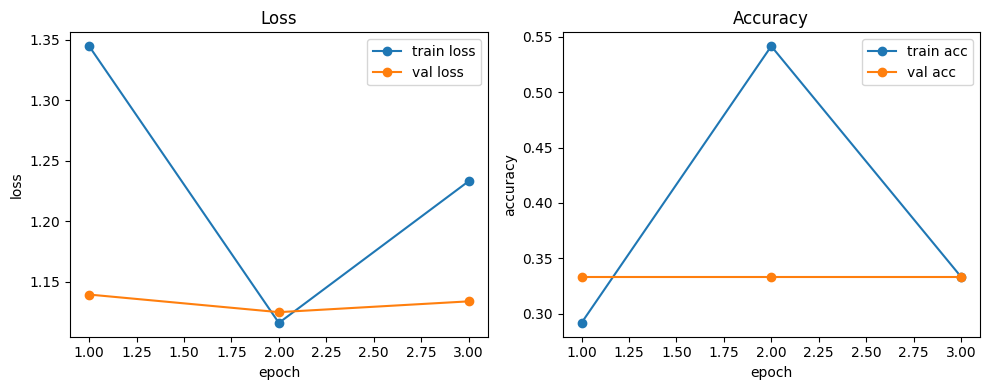

In [ ]:

import matplotlib.pyplot as plt
epochs_ = [h['epoch'] for h in history]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(epochs_, [h['tr_loss'] for h in history], label='train loss', marker='o')
axes[0].plot(epochs_, [h['val_loss'] for h in history], label='val loss', marker='o')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('loss'); axes[0].legend(); axes[0].set_title('Loss')
axes[1].plot(epochs_, [h['tr_acc'] for h in history], label='train acc', marker='o')
axes[1].plot(epochs_, [h['val_acc'] for h in history], label='val acc', marker='o')
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('accuracy'); axes[1].legend(); axes[1].set_title('Accuracy')
plt.tight_layout(); plt.show()

## 7. Test-set evaluation (Sec 5.1)

In [ ]:
model.load_state_dict(torch.load("/kaggle/working/posevit_x_best.pt"))
test_loss, test_acc, test_f1 = run_epoch(model, test_loader)
print(f"Test accuracy: {test_acc:.4f} | Test macro-F1: {test_f1:.4f}")

# full per-class report
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for img, lm, fskel, y in test_loader:
        img, lm = img.to(DEVICE), lm.to(DEVICE)
        logits = model(img, lm)
        all_preds.append(logits.argmax(1).cpu().numpy())
        all_labels.append(y.numpy())
all_preds = np.concatenate(all_preds)
all_labels = np.concatenate(all_labels)
print(classification_report(all_labels, all_preds, target_names=classes, zero_division=0))

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:01<00:00,  1.03s/it]

Test accuracy: 0.3333 | Test macro-F1: 0.1667


              precision    recall  f1-score   support

  chair_pose       0.33      1.00      0.50         1
   tree_pose       0.00      0.00      0.00         1
  warrior_ii       0.00      0.00      0.00         1

    accuracy                           0.33         3
   macro avg       0.11      0.33      0.17         3
weighted avg       0.11      0.33      0.17         3



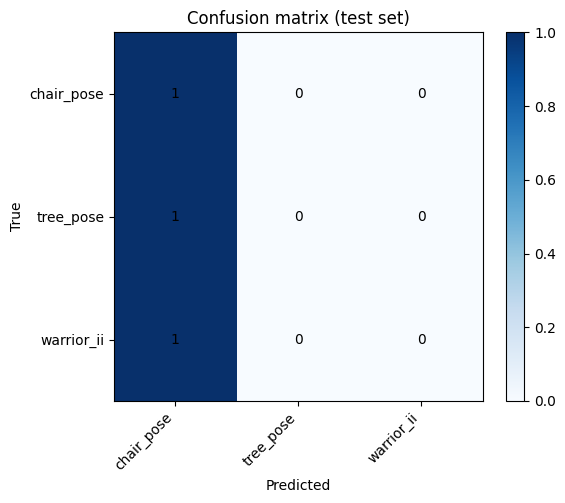

In [ ]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=45, ha='right')
ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title('Confusion matrix (test set)')
for r in range(cm.shape[0]):
    for c_ in range(cm.shape[1]):
        ax.text(c_, r, str(cm[r, c_]), ha='center', va='center')
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

## 8. Cross-dataset generalisation on the Kaggle AI Yoga Trainer set (Sec 5.5)

This mirrors the paper's zero-shot cross-dataset test: no fine-tuning, just direct inference on
the AI Yoga Trainer classes that overlap with your Yoga-82 taxonomy. Classes that don't overlap are
reported separately rather than silently dropped.

In [ ]:
aiyoga_df = index_folder_dataset(AIYOGA_ROOT)
print("AI Yoga Trainer images found:", len(aiyoga_df))
print(aiyoga_df["label_raw"].unique())

overlap = [c for c in aiyoga_df["label_raw"].unique() if c in label2idx]
missing = [c for c in aiyoga_df["label_raw"].unique() if c not in label2idx]
print(f"{len(overlap)} classes overlap with the Yoga-82 taxonomy; {len(missing)} do not: {missing}")

eval_df = aiyoga_df[aiyoga_df["label_raw"].isin(overlap)].copy()
eval_df["label"] = eval_df["label_raw"].map(label2idx)
precache_landmarks(eval_df, "cross-dataset landmarks")

cross_ds = YogaDataset(eval_df, eval_tf)
cross_loader = DataLoader(cross_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
_, cross_acc, cross_f1 = run_epoch(model, cross_loader)
print(f"Cross-dataset accuracy on AI Yoga Trainer overlap classes: {cross_acc:.4f} (F1 {cross_f1:.4f})")

AI Yoga Trainer images found: 8
<StringArray>
['warrior_ii', 'tree_pose']
Length: 2, dtype: str
2 classes overlap with the Yoga-82 taxonomy; 0 do not: []


cross-dataset landmarks:   0%|          | 0/8 [00:00<?, ?it/s]

cross-dataset landmarks: 100%|██████████| 8/8 [00:00<00:00, 823.06it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

 50%|█████     | 1/2 [00:01<00:01,  1.61s/it]

100%|██████████| 2/2 [00:02<00:00,  1.47s/it]

Cross-dataset accuracy on AI Yoga Trainer overlap classes: 0.0000 (F1 0.0000)


## 9. Explainability — attention-rollout Grad-CAM over the joint image+landmark sequence (Sec 3.5.1)

Since ViT has no convolutional feature maps, saliency is computed as a gradient-weighted
combination of the attention maps from the final encoder block, over **both** the image-patch
tokens and the landmark tokens — so you get a heatmap over the image and an importance score
per joint.

In [ ]:
def vit_gradcam(model, img, lm, target_class=None):
    model.eval()
    img = img.clone().requires_grad_(False)
    logits, attn_maps = model(img, lm, return_attn=True)
    if target_class is None:
        target_class = logits.argmax(1)
    score = logits[torch.arange(logits.size(0)), target_class].sum()

    last_attn = attn_maps[-1]                     # (B, heads, N, N)
    last_attn.retain_grad()
    model.zero_grad()
    score.backward(retain_graph=True)
    grads = last_attn.grad                          # (B, heads, N, N)

    weights = grads.mean(dim=(2, 3), keepdim=True)   # spatial average of the gradient per head
    cam = F.relu((weights * last_attn)).mean(dim=1)   # (B, N, N) averaged over heads
    cam_cls = cam[:, 0, :]                            # attention from CLS token to all other tokens

    n_patches = model.patch_embed.num_patches         # 196
    patch_cam = cam_cls[:, 1:1 + n_patches]            # (B, 196)
    landmark_cam = cam_cls[:, 1 + n_patches:]          # (B, 33)

    side = int(math.sqrt(n_patches))                  # 14
    patch_cam_2d = patch_cam.reshape(-1, side, side).detach().cpu().numpy()
    landmark_cam = landmark_cam.detach().cpu().numpy()
    return patch_cam_2d, landmark_cam, target_class.detach().cpu().numpy()


def overlay_gradcam(image_uint8_224, patch_cam_2d):
    heat = cv2.resize(patch_cam_2d, (224, 224))
    heat = (heat - heat.min()) / (heat.max() - heat.min() + 1e-8)
    heat_color = cv2.applyColorMap((heat * 255).astype(np.uint8), cv2.COLORMAP_JET)
    overlay = cv2.addWeighted(image_uint8_224, 0.6, heat_color, 0.4, 0)
    return overlay

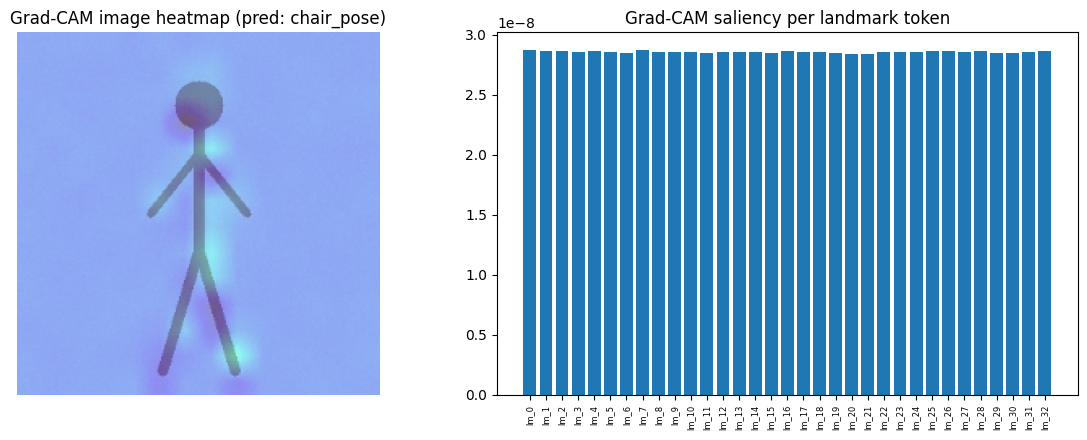

In [ ]:

import matplotlib.pyplot as plt
_gc_path = test_df.iloc[0]['path']
_gc_img_bgr = cv2.imread(_gc_path)
_gc_img_rgb = cv2.cvtColor(_gc_img_bgr, cv2.COLOR_BGR2RGB)
_gc_img_224 = cv2.resize(_gc_img_rgb, (224, 224))
_gc_lm, _gc_fskel = extract_and_cache(_gc_path)
_gc_lm_t = torch.from_numpy(_gc_lm[:, :3]).unsqueeze(0).to(DEVICE)
_gc_norm = (_gc_img_224.astype(np.float32) / 255.0 - np.array(IMAGENET_MEAN)) / np.array(IMAGENET_STD)
_gc_img_t = torch.tensor(_gc_norm.transpose(2, 0, 1)).unsqueeze(0).float().to(DEVICE)

patch_cam_2d, landmark_cam, pred = vit_gradcam(model, _gc_img_t, _gc_lm_t)
overlay = overlay_gradcam(_gc_img_224.copy(), patch_cam_2d[0])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].imshow(overlay[..., ::-1]); axes[0].axis('off')
axes[0].set_title(f'Grad-CAM image heatmap (pred: {classes[pred[0]]})')

joint_names = [n for n, *_ in JOINT_ANGLE_TRIPLES] + [n for n, *_ in LIMB_RATIO_QUADS][:33 - len(JOINT_ANGLE_TRIPLES)]
joint_names = [f'lm_{k}' for k in range(landmark_cam.shape[1])]  # 33 raw BlazePose landmark tokens, not the 29-d F_skel names
axes[1].bar(range(len(joint_names)), landmark_cam[0])
axes[1].set_xticks(range(len(joint_names))); axes[1].set_xticklabels(joint_names, rotation=90, fontsize=6)
axes[1].set_title('Grad-CAM saliency per landmark token')
plt.tight_layout(); plt.show()

## 10. Explainability — LIME (image-space and landmark-space), Sec 3.5.2

In [ ]:
from lime import lime_image
from lime.lime_tabular import LimeTabularExplainer
from skimage.segmentation import slic

def model_predict_proba_for_lime(images_uint8_batch, fixed_lm):
    '''images_uint8_batch: (N, 224, 224, 3) uint8 RGB, as produced by LIME's perturbation loop.
    fixed_lm: the (33, 3) landmark tensor for the *original* image, broadcast across perturbations
    (LIME perturbs pixels only in the visual channel, per the paper's Sec 3.5.2 image pathway).'''
    model.eval()
    imgs = []
    for im in images_uint8_batch:
        norm = (im.astype(np.float32) / 255.0 - np.array(IMAGENET_MEAN)) / np.array(IMAGENET_STD)
        imgs.append(norm.transpose(2, 0, 1))
    batch = torch.tensor(np.stack(imgs), dtype=torch.float32).to(DEVICE)
    lm_batch = fixed_lm.unsqueeze(0).repeat(batch.size(0), 1, 1).to(DEVICE)
    with torch.no_grad():
        logits = model(batch, lm_batch)
        probs = F.softmax(logits, dim=1).cpu().numpy()
    return probs


def explain_image_lime(image_224_uint8_rgb, lm_tensor, num_samples=1000):
    explainer = lime_image.LimeImageExplainer()
    segmentation_fn = lambda x: slic(x, n_segments=100, compactness=10)
    explanation = explainer.explain_instance(
        image_224_uint8_rgb,
        classifier_fn=lambda batch: model_predict_proba_for_lime(batch, lm_tensor),
        top_labels=1, hide_color=0, num_samples=num_samples,
        segmentation_fn=segmentation_fn,
    )
    label = explanation.top_labels[0]
    temp, mask = explanation.get_image_and_mask(label, positive_only=False, num_features=5, hide_rest=False)
    return temp, mask, label


def explain_landmarks_lime(fskel_row, train_fskel_matrix, feature_names, predict_fn_tabular, num_samples=500):
    '''Geometric LIME over the 29-d hand-crafted joint-angle/limb-ratio descriptor.
    predict_fn_tabular(X: np.ndarray[N,29]) -> np.ndarray[N, num_classes] probabilities.'''
    explainer = LimeTabularExplainer(
        training_data=train_fskel_matrix,
        feature_names=feature_names,
        mode="classification",
        discretize_continuous=False,
    )
    exp = explainer.explain_instance(fskel_row, predict_fn_tabular, num_features=len(feature_names),
                                      num_samples=num_samples)
    return exp.as_list()

  0%|          | 0/15 [00:00<?, ?it/s]

 67%|██████▋   | 10/15 [00:03<00:01,  3.04it/s]

100%|██████████| 15/15 [00:03<00:00,  4.54it/s]

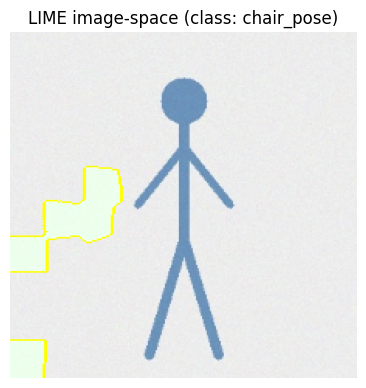

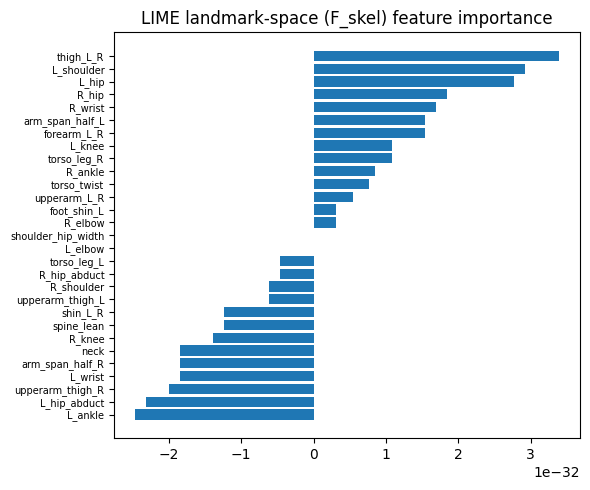

In [ ]:


# --- image-space LIME ---
import matplotlib.pyplot as plt
from skimage.segmentation import mark_boundaries

_lime_path = test_df.iloc[0]['path']
_lime_img_bgr = cv2.imread(_lime_path)
_lime_img_224 = cv2.resize(cv2.cvtColor(_lime_img_bgr, cv2.COLOR_BGR2RGB), (224, 224))
_lime_lm, _lime_fskel = extract_and_cache(_lime_path)
_lime_lm_t = torch.from_numpy(_lime_lm[:, :3])

temp, mask, lime_label = explain_image_lime(_lime_img_224, _lime_lm_t, num_samples=15)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.imshow(mark_boundaries(temp / 255.0, mask))
ax.axis('off'); ax.set_title(f'LIME image-space (class: {classes[lime_label]})')
plt.show()


train_lms, train_fskels = [], []
for p in train_df['path'].tolist():
    lm_, fskel_ = extract_and_cache(p)
    train_lms.append(lm_[:, :3]); train_fskels.append(fskel_)
train_lms = np.stack(train_lms); train_fskels = np.stack(train_fskels)
feature_names = [n for n, *_ in JOINT_ANGLE_TRIPLES] + [n for n, *_ in LIMB_RATIO_QUADS]

def predict_fn_tabular_demo(X):

    d = ((train_fskels[None, :, :] - X[:, None, :]) ** 2).sum(-1)
    nn_idx = d.argmin(axis=1)
    lm_batch = torch.tensor(train_lms[nn_idx], dtype=torch.float32).to(DEVICE)
    img_batch = _lime_img_t = torch.tensor(
        ((_lime_img_224.astype(np.float32) / 255.0 - np.array(IMAGENET_MEAN)) / np.array(IMAGENET_STD))
        .transpose(2, 0, 1)
    ).unsqueeze(0).float().to(DEVICE).repeat(X.shape[0], 1, 1, 1)
    with torch.no_grad():
        probs = F.softmax(model(img_batch, lm_batch), dim=1).cpu().numpy()
    return probs

landmark_exp = explain_landmarks_lime(_lime_fskel, train_fskels, feature_names,
                                       predict_fn_tabular_demo, num_samples=20)
names_, weights_ = zip(*landmark_exp)
fig, ax = plt.subplots(figsize=(6, 5))
order = np.argsort(weights_)
ax.barh(range(len(names_)), np.array(weights_)[order])
ax.set_yticks(range(len(names_))); ax.set_yticklabels(np.array(names_)[order], fontsize=7)
ax.set_title('LIME landmark-space (F_skel) feature importance')
plt.tight_layout(); plt.show()

## 11. Corrective Feedback Decoder (Sec 3.5.3)

Architecture exactly as specified: 3-layer MLP, 34-d input (17 Grad-CAM joint saliencies +
17 LIME geometric importances), 15-way joint-error output. **Public data has no ground-truth
joint-error labels**, so this cell trains the MLP only if you supply a labelled CSV (columns:
34 feature columns + `error_label` in [0, 14]); otherwise it falls back to a transparent
rule-based angle-threshold heuristic so the demo below still produces feedback text.

In [ ]:
JOINT_ERROR_CLASSES = [
    "hyperextension", "valgus_collapse", "pelvic_tilt", "thoracic_rounding",
    "shoulder_asymmetry", "knee_varus", "ankle_pronation", "lumbar_overextension",
    "cervical_forward_lean", "hip_hike", "elbow_hyperextension", "foot_arch_collapse",
    "scapular_winging", "weight_imbalance", "spinal_rotation_excess",
]
assert len(JOINT_ERROR_CLASSES) == 15

CORRECTION_TEMPLATES = {
    "hyperextension":        "Soften the joint slightly — you're locking it past neutral extension.",
    "valgus_collapse":       "Track the knee outward over the second toe; it's drifting inward.",
    "pelvic_tilt":           "Level the pelvis — engage the lower abdominals to reduce the anterior tilt.",
    "thoracic_rounding":     "Lift through the sternum to reduce rounding in the upper back.",
    "shoulder_asymmetry":    "Square the shoulders — one side is riding higher than the other.",
    "knee_varus":            "Guide the knee back in line with the hip and ankle.",
    "ankle_pronation":       "Distribute weight evenly across the foot; the ankle is rolling inward.",
    "lumbar_overextension":  "Draw the lower ribs down to reduce the arch in your lower back.",
    "cervical_forward_lean": "Draw the chin back slightly to align the neck over the shoulders.",
    "hip_hike":              "Release the lifted hip and lengthen evenly through both sides of the waist.",
    "elbow_hyperextension":  "Keep a micro-bend in the elbow instead of locking it out.",
    "foot_arch_collapse":    "Press through the outer edge of the foot to lift the inner arch.",
    "scapular_winging":      "Draw the shoulder blade flat against the ribcage.",
    "weight_imbalance":      "Shift weight back toward centre — you're leaning to one side.",
    "spinal_rotation_excess":"Ease off the twist slightly to keep the spine's rotation within a safe range.",
}


class CorrectiveFeedbackDecoder(nn.Module):
    def __init__(self, in_dim=34, num_errors=15):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64), nn.ReLU(inplace=True),
            nn.Linear(64, 32), nn.ReLU(inplace=True),
            nn.Linear(32, num_errors),
        )

    def forward(self, x):
        return torch.sigmoid(self.net(x))    # multi-label activation probabilities


def rule_based_feedback(joint_angles_deg, angle_ref_ranges):
    '''Transparent fallback: flag joints outside a clinically-typical angle range.
    angle_ref_ranges: dict[joint_name] -> (low, high) in degrees.'''
    flags = []
    for name, (lo, hi) in angle_ref_ranges.items():
        val = joint_angles_deg.get(name)
        if val is None:
            continue
        if val < lo or val > hi:
            flags.append((name, val, lo, hi))
    return flags


def generate_feedback(cfd_model, gradcam_joint_scores, lime_joint_scores, top_k=3):
    '''gradcam_joint_scores, lime_joint_scores: length-17 np arrays aligned to JOINT_ANGLE_TRIPLES order.'''
    x = np.concatenate([gradcam_joint_scores, lime_joint_scores]).astype(np.float32)  # (34,)
    x_t = torch.from_numpy(x).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        probs = cfd_model(x_t).cpu().numpy()[0]
    top_idx = np.argsort(-probs)[:top_k]
    messages = [f"{CORRECTION_TEMPLATES[JOINT_ERROR_CLASSES[i]]}" for i in top_idx]
    return list(zip([JOINT_ERROR_CLASSES[i] for i in top_idx], probs[top_idx], messages))


cfd_model = CorrectiveFeedbackDecoder().to(DEVICE)


## 12. End-to-end inference demo on a single frame

Predicted pose: chair_pose (47.0% confidence)


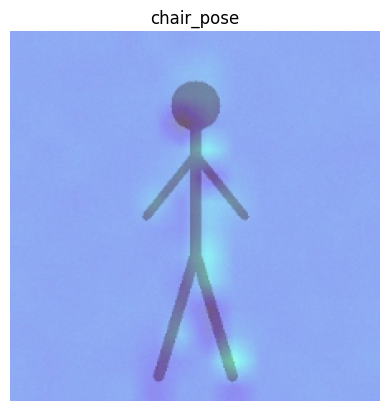

In [ ]:
def run_full_pipeline(image_path):
    img_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_224 = cv2.resize(img_rgb, (224, 224))

    lm, fskel = extract_and_cache(image_path)
    lm_t = torch.from_numpy(lm[:, :3]).unsqueeze(0).to(DEVICE)

    norm = (img_224.astype(np.float32) / 255.0 - np.array(IMAGENET_MEAN)) / np.array(IMAGENET_STD)
    img_t = torch.tensor(norm.transpose(2, 0, 1)).unsqueeze(0).float().to(DEVICE)

    with torch.no_grad():
        logits = model(img_t, lm_t)
        pred_idx = logits.argmax(1).item()
        pred_class = classes[pred_idx]
        confidence = F.softmax(logits, dim=1)[0, pred_idx].item()

    patch_cam_2d, landmark_cam, _ = vit_gradcam(model, img_t, lm_t, target_class=torch.tensor([pred_idx]).to(DEVICE))
    overlay = overlay_gradcam(img_224.copy(), patch_cam_2d[0])

    print(f"Predicted pose: {pred_class} ({confidence*100:.1f}% confidence)")
    return overlay, landmark_cam[0], pred_class, confidence


overlay, landmark_saliency, pred_class, conf = run_full_pipeline(test_df.iloc[0]["path"])
import matplotlib.pyplot as plt  # DRY-RUN PATCH: uncommented; inline backend renders this in the notebook
plt.imshow(overlay[..., ::-1]); plt.axis("off"); plt.title(pred_class); plt.show()